# Mini-FM results: overview

Figures and tables of the report, rebuilt from the small files in
[`experiments/fm_mini/results/`](../experiments/fm_mini/results) (no data, checkpoints or GPU needed).
The same tables as text: [`results/tables.md`](../experiments/fm_mini/results/tables.md), produced by
[`paper_tables.py`](../experiments/fm_mini/paper_tables.py), which this notebook also uses.

**Setup.** Models are trained on windows of 9 sources of the pretraining corpus (context 512, horizon 96) and tested
on new series of the same sources (**ID**) and zero-shot on 6 held-out sources (**OOD**).
**Skill** = geometric mean over sources of mean CRPS / mean CRPS of seasonal-naive; lower is better.

**Models.** **DV-FM**: the original DecoVAE-FM (trend, seasonal and noise streams). **TF-2L / TF-6L**: its trend
Transformer alone, with 2 or 6 layers (TF-6L has the size of DV-FM). **PD**: period-aware decomposition, ours: the
seasonal part is computed from the window (estimated periods + Fourier fit) and the network learns the rest.
Loss suffixes: none = Gaussian NLL, **-Mix** = log score of the mixture over 8 latent draws, **-MixC** = -Mix plus
almost-fair CRPS of the same mixture.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

FM = Path('..')/'experiments'/'fm_mini'
sys.path.insert(0, str(FM))
import paper_tables as P

R = FM/'results'
COL = {'TF-6L': 'C0', 'TF-6L-MixC': 'C0', 'PD': 'C3', 'PD-MixC': 'C1', 'DV-FM': 'C7', 'TF-2L': 'C9'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .3, 'legend.frameon': False, 'font.size': 9})
TABLES = P.all_tables()
def show(title_start):
    for title, t in TABLES.items():
        if title.startswith(title_start): display(Markdown(f'**{title}**')); display(t)

## 1. Main comparison

PD against the plain Transformer of the same size, at the same loss. On held-out sources PD is 13-16% better; on
familiar sources it is about 3% worse.

**Main comparison: PD vs TF-6L at the same loss (skill mean ± sd over seeds; ratio with 95% CI)**

,model,seeds,OOD skill,OOD ratio PD/TF-6L,ID skill,ID ratio PD/TF-6L
loss,,,,,,
NLL,TF-6L,5,0.788 ± 0.021,,0.440 ± 0.007,
NLL,PD,5,0.674 ± 0.004,0.854 [0.836; 0.871],0.456 ± 0.004,1.037 [1.019; 1.066]
Mix,TF-6L,5,0.773 ± 0.016,,0.429 ± 0.005,
Mix,PD,5,0.651 ± 0.004,0.841 [0.823; 0.858],0.440 ± 0.004,1.025 [1.009; 1.045]
MixC,TF-6L,5,0.747 ± 0.015,,0.418 ± 0.006,
MixC,PD,5,0.649 ± 0.004,0.868 [0.850; 0.885],0.430 ± 0.006,1.029 [1.007; 1.058]
,DV-FM (NLL),5,0.785 ± 0.015,,0.444 ± 0.013,
,TF-6L-Mix + 50% KernelSynth,5,0.733 ± 0.017,,0.424 ± 0.005,
,ES+Fourier (no training),,0.716,,0.571,


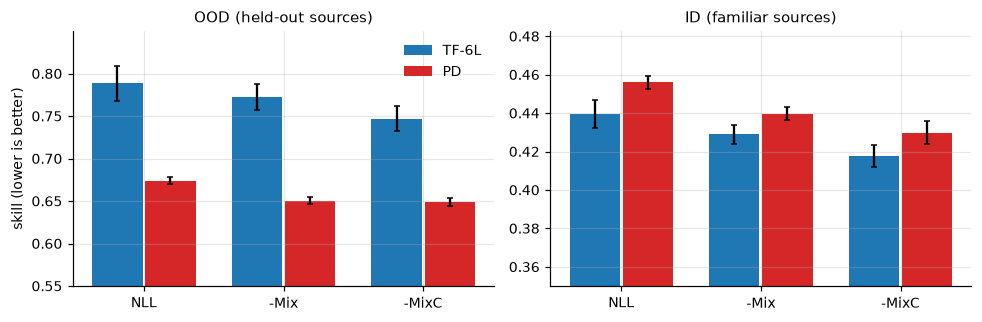

In [2]:
show('Main comparison')
fig, ax = plt.subplots(1, 2, figsize=(9, 3), sharey=False)
for a, split, title in ((ax[0], 'test_ood', 'OOD (held-out sources)'), (ax[1], 'test_id', 'ID (familiar sources)')):
    for j, (loss, (tf, pd_)) in enumerate(P.MAIN.items()):
        for k, (name, fam) in enumerate((('TF-6L', tf), ('PD', pd_))):
            m, s, n = P.family_skill(fam, split)
            a.bar(j + (k - .5)*.38, m, .36, yerr=s, color=COL[name], capsize=2, label=name if j == 0 else None)
    a.set_xticks(range(3)); a.set_xticklabels(['NLL', '-Mix', '-MixC']); a.set_title(title, fontsize=10)
    a.set_ylim(.35 if split == 'test_id' else .55, None)
ax[0].set_ylabel('skill (lower is better)'); ax[0].legend()
fig.tight_layout()

## 2. Where the gain comes from: per source

Ratio of the per-source skill PD-MixC / TF-6L-MixC (seed means); below 1 means PD is better. The large OOD gains are
on strongly periodic sources (Electricity, Solar); the ID cost comes mostly from largest_2017 (cycle of 288 steps,
longer than a third of the context) and Q-TRAFFIC (period missed in some windows).

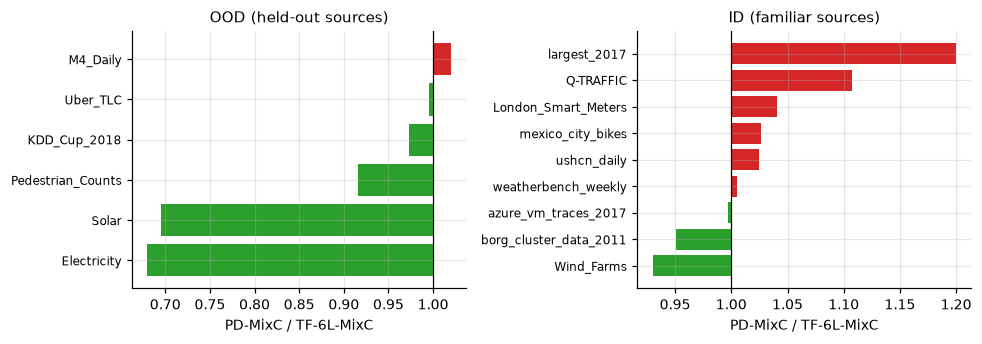

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, split in zip(ax, ('test_ood', 'test_id')):
    t = TABLES[f'Skill per source, {P.SPLITS[split]} (seed means)']['PD-MixC / TF-6L-MixC'].sort_values()
    a.barh(range(len(t)), t.values - 1, left=1, color=['C2' if v < 1 else 'C3' for v in t.values])
    a.axvline(1, color='k', lw=.8); a.set_yticks(range(len(t))); a.set_yticklabels(t.index, fontsize=8)
    a.set_title(P.SPLITS[split], fontsize=10); a.set_xlabel('PD-MixC / TF-6L-MixC')
fig.tight_layout()

## 3. Forecasts of the main pair (figure of the report)

For each of four OOD sources the window with the median CRPS ratio PD-MixC / TF-6L-MixC, i.e. a typical window
(rule fixed before plotting). Seed 0, normalised units, last 192 context steps.

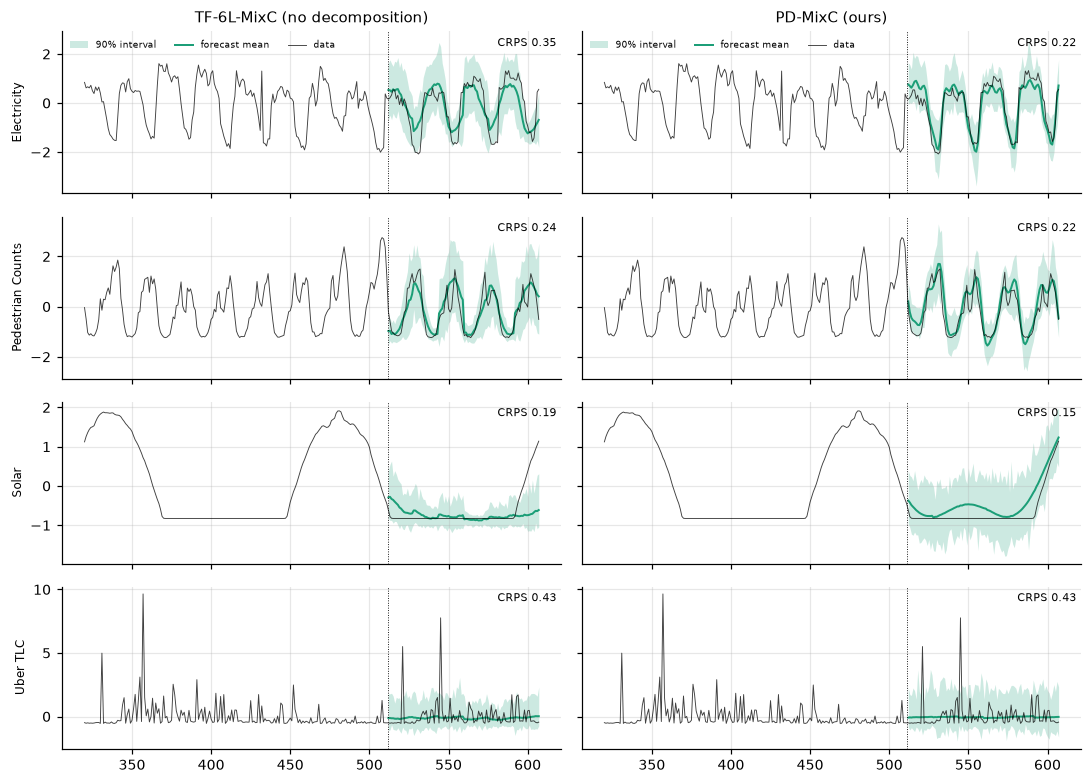

In [4]:
d = np.load(R/'fig_forecasts.npz', allow_pickle=True); T = 512
x = d['x'].astype(float); m = x[:, :T].mean(1); s = x[:, :T].std(1); s[s < 1e-8] = 1
z = np.clip((x - m[:, None])/s[:, None], -20, 20); t = np.arange(x.shape[1]); full = slice(T - 192, None); hor = slice(T, None)
fig, ax = plt.subplots(len(x), 2, figsize=(10, 1.8*len(x)), sharex=True, sharey='row')
for r in range(len(x)):
    for c, (key, title) in enumerate((('tf', 'TF-6L-MixC (no decomposition)'), ('pd', 'PD-MixC (ours)'))):
        a = ax[r, c]; nz = lambda v: (v - m[r])/s[r]
        a.fill_between(t[hor], nz(d[f'{key}_q05'][r]), nz(d[f'{key}_q95'][r]), color='#1b9e77', alpha=.22, lw=0, label='90% interval')
        a.plot(t[hor], nz(d[f'{key}_mean'][r]), color='#1b9e77', lw=1.3, label='forecast mean')
        a.plot(t[full], z[r, full], color='k', lw=.6, alpha=.75, label='data'); a.axvline(T - .5, color='k', lw=.6, ls=':')
        a.text(.99, .96, f"CRPS {d[f'{key}_ncrps'][r]:.2f}", transform=a.transAxes, ha='right', va='top', fontsize=7)
        if c == 0: a.set_ylabel(str(d['dataset'][r]).replace('_', ' '), fontsize=8)
        if r == 0: a.set_title(title, fontsize=10); a.legend(fontsize=6, loc='upper left', ncol=3)
fig.tight_layout()

## 4. Decomposition on the synthetic lab (figure of the report)

Lab windows with known components: linear trend + short cycle + long wave + noise. A long wave with at least three
cycles in the window should go to the seasonal part, a longer one to the trend. Both models trained on the lab,
seed 0, first window of three lab cells. DV-FM puts everything into its trend stream; PD recovers both parts and
forecasts a cycle with a period never seen in training.

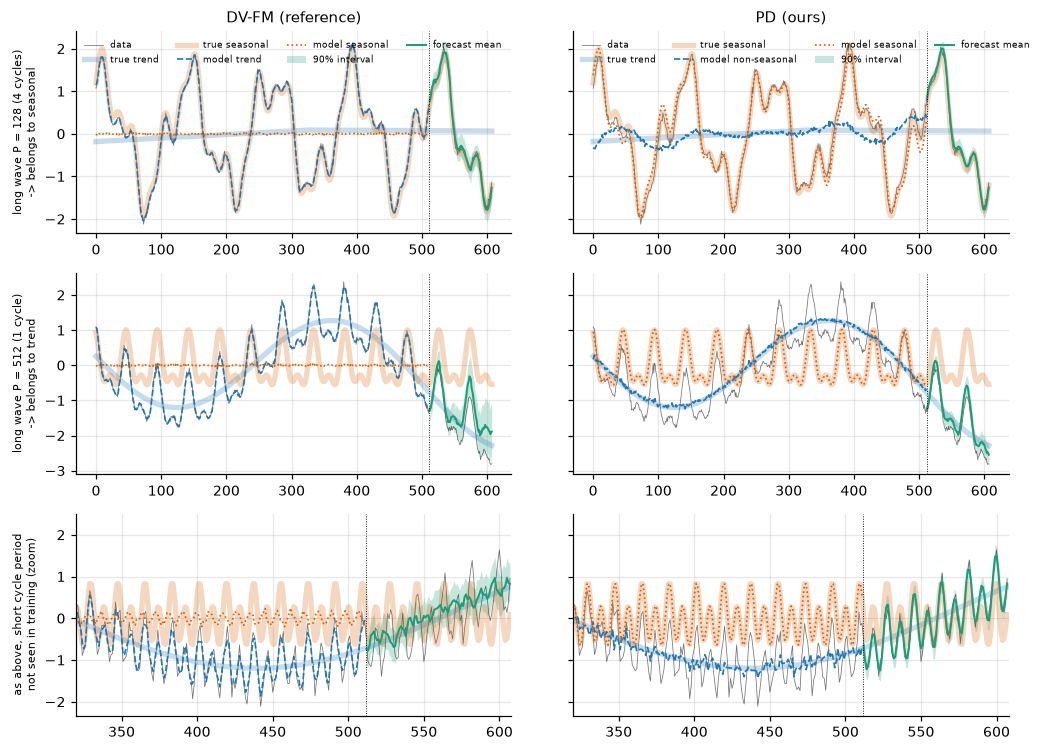

In [5]:
d = np.load(R/'fig_lab_windows.npz'); T = 512
rows = [('test_id_P128_r2', 'long wave P = 128 (4 cycles)\n-> belongs to seasonal'),
        ('test_id_P512_r2', 'long wave P = 512 (1 cycle)\n-> belongs to trend'),
        ('test_ood_P512_r2', 'as above, short cycle period\nnot seen in training (zoom)')]
models = [('lab_A_s0', 'DV-FM (reference)'), ('lab_Dcomb_s0', 'PD (ours)')]
t = np.arange(len(d['test_id_P128_r2_x'])); hor = slice(T, None)
fig, ax = plt.subplots(len(rows), 2, figsize=(10, 2.3*len(rows)), sharey='row')
for r, (k, lab) in enumerate(rows):
    for c, (run, title) in enumerate(models):
        a = ax[r, c]; dec = d[f'{k}_{run}_dec']; q = d[f'{k}_{run}_q']
        a.plot(t, d[k + '_x'], color='k', lw=.5, alpha=.55, label='data')
        a.plot(t, d[k + '_trend_true'], color='#1f77b4', lw=3.5, alpha=.25, label='true trend')
        a.plot(t, d[k + '_seas_true'], color='#d95f02', lw=3.5, alpha=.25, label='true seasonal')
        a.plot(t[:T], dec[0, :T], color='#1f77b4', lw=1.1, ls='--', label='model trend' if c == 0 else 'model non-seasonal')
        a.plot(t[:T], dec[1, :T], color='#d95f02', lw=1.1, ls=':', label='model seasonal')
        a.fill_between(t[hor], q[0], q[2], color='#1b9e77', alpha=.25, lw=0, label='90% interval')
        a.plot(t[hor], d[f'{k}_{run}_mean'], color='#1b9e77', lw=1.3, label='forecast mean'); a.axvline(T - .5, color='k', lw=.6, ls=':')
        if c == 0: a.set_ylabel(lab, fontsize=7)
        if r == 0: a.set_title(title, fontsize=10)
        if r == 2: a.set_xlim(320, len(t))
        if r == 0: a.legend(fontsize=6, loc='upper left', ncol=4)
fig.tight_layout()

## 5. Lab: forecasts on seen and new periods (figure of the report)

CRPS divided by the CRPS of the true distribution (1 is perfect), mean over windows and 3 seeds with a bootstrap 95%
interval of the mean; c80 is the coverage of the 80% interval. The plain model memorises the training periods; on new
periods only the computed decomposition keeps working.

**Synthetic lab, models trained on the lab (wave share: P = 128 -> 1, P >= 192 -> 0; CRPS / true distribution)**

,seeds,share_P128,share_P192plus,seen_crps_true,seen_c80,new_crps_true,new_c80
model,,,,,,,
DV-FM,3,0.0,-0.0,2.713,0.865,10.11,0.379
TF-6L,3,NaN,NaN,1.799,0.831,11.032,0.237
PD,3,0.814,0.013,2.363,0.812,3.388,0.729
PD-MixC,3,0.815,0.013,2.36,0.797,3.181,0.725


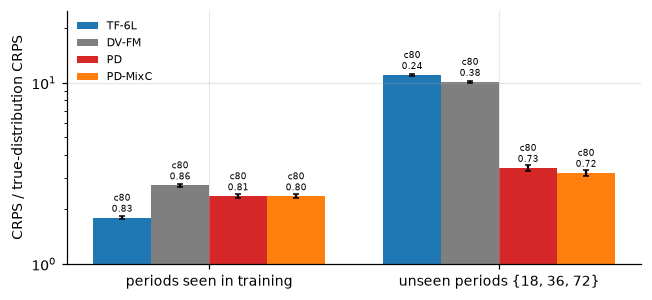

In [6]:
show('Synthetic lab')
lab = pd.read_parquet(R/'lab_scores.parquet'); lab['run'] = lab.run.astype(str)
def ci(v, n=1000, seed=0):
    v = np.asarray(v, float); v = v[np.isfinite(v)]; rng = np.random.default_rng(seed)
    b = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(n)]; return v.mean(), *np.quantile(b, [.025, .975])
fig, ax = plt.subplots(figsize=(6, 2.8)); w = .2
for j, (name, fam) in enumerate((('TF-6L', 'lab_N6r02'), ('DV-FM', 'lab_A'), ('PD', 'lab_Dcomb'), ('PD-MixC', 'lab_Dmc1'))):
    d = lab[lab.run.str.match(fam + r'_s\d+$')]
    for i, split in enumerate(('test_id', 'test_ood')):
        g = d[d.split == split]; mu, lo, hi = ci(g.crps_ratio); x = i + (j - 1.5)*w
        ax.bar(x, mu, w, yerr=[[mu - lo], [hi - mu]], color=COL[name], capsize=2, label=name if i == 0 else None)
        ax.text(x, mu*1.08, f'c80\n{g.c80.mean():.2f}', ha='center', fontsize=6)
ax.set_yscale('log'); ax.set_xticks([0, 1]); ax.set_xticklabels(['periods seen in training', 'unseen periods {18, 36, 72}'])
ax.set_ylabel('CRPS / true-distribution CRPS'); ax.set_ylim(1, 25); ax.legend(fontsize=7, loc='upper left')
fig.tight_layout()

## 6. Is it a lack of diverse data? KernelSynth (figure of the report)

Synthetic Gaussian-process windows (KernelSynth, as in Chronos) added as 25, 50 or 100% extra training windows, NLL
loss. TF-6L gains on OOD, PD does not change: synthetic data close about a third of the gap.

**Against the plain model with synthetic data**

,OOD (held-out sources),ID (familiar sources)
comparison,,
PD-MixC / TF-6L-Mix + 50% KernelSynth,0.884 [0.867; 0.902],1.014 [0.990; 1.033]
PD / TF-6L + 50% KernelSynth,0.900 [0.882; 0.917],1.056 [1.034; 1.088]


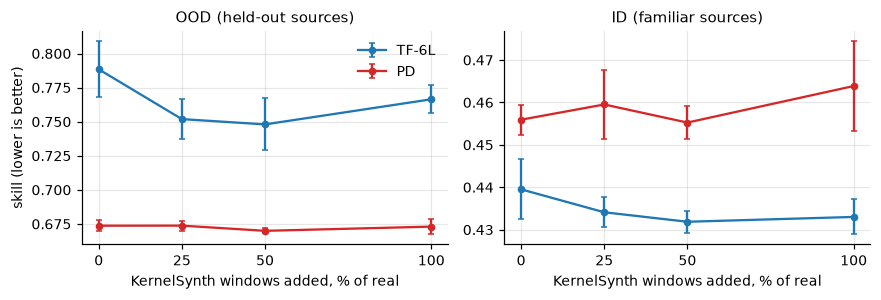

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
for a, split in zip(ax, ('test_ood', 'test_id')):
    for name, fams in P.KERNELSYNTH.items():
        v = [P.family_skill(f, split) for f in fams]
        a.errorbar([0, 25, 50, 100], [m for m, _, _ in v], yerr=[s for _, s, _ in v], marker='o', ms=4, capsize=2, color=COL[name], label=name)
    a.set_title(P.SPLITS[split], fontsize=10); a.set_xlabel('KernelSynth windows added, % of real'); a.set_xticks([0, 25, 50, 100])
ax[0].set_ylabel('skill (lower is better)'); ax[0].legend()
fig.tight_layout()
show('Against the plain model')

## 7. Forecast distribution: calibration

PIT histograms on OOD (pooled over sources and seeds; flat = calibrated). Single-draw NLL training gives a hump in
the middle (centre too wide) and too few points in the far tails; the latent-mixture loss (-Mix / -MixC) flattens it.

**Forecast distribution on OOD (mean over seeds; targets CCE 0, c50 .50, c80 .80, c98 .98)**

,skill,PCE,CCE,c50,c80,c98,ES,VS,latent
model,,,,,,,,,
TF-6L,0.788,0.048,-0.029,0.560,0.799,0.911,6.55,0.278,0.001
TF-6L-MixC,0.747,0.046,+0.001,0.508,0.803,0.953,6.35,0.250,0.157
PD,0.674,0.043,-0.043,0.576,0.810,0.932,5.65,0.232,0.001
PD-Mix,0.651,0.034,-0.007,0.515,0.815,0.963,5.65,0.232,0.064
PD-CRPS,0.657,0.036,+0.062,0.428,0.746,0.946,5.57,0.197,0.086
PD-MixC,0.649,0.034,+0.002,0.504,0.808,0.961,5.60,0.222,0.051
PD-CVAE-S,0.674,0.047,-0.018,0.544,0.787,0.922,5.59,0.208,0.185
PD-CVAE-G,0.662,0.047,-0.031,0.562,0.803,0.930,5.54,0.199,0.271


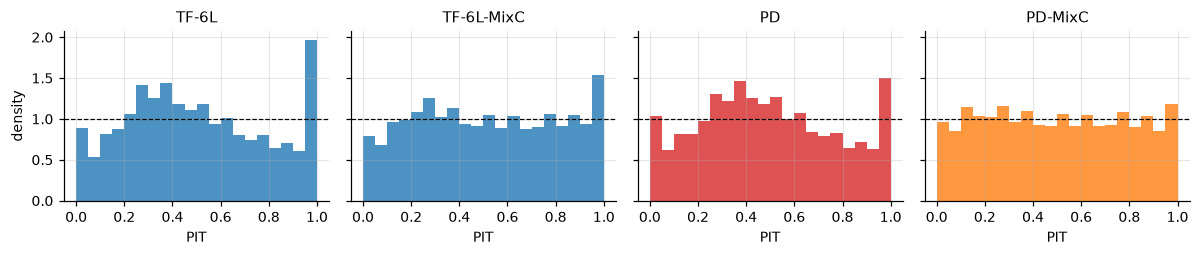

In [8]:
show('Forecast distribution')
cal = P.calibration(); bins = [c for c in cal.columns if c.startswith('pit')]
names = ['TF-6L', 'TF-6L-MixC', 'PD', 'PD-MixC']
fig, ax = plt.subplots(1, len(names), figsize=(11, 2.4), sharey=True)
for a, name in zip(ax, names):
    rs = P.members(P.UNCERTAINTY[name]); h = cal[cal.run.isin(rs) & (cal.split == 'test_ood')][bins].sum().values
    h = h/h.sum()*len(bins); a.bar(np.arange(len(bins))/len(bins), h, 1/len(bins), align='edge', color=COL[name], alpha=.8)
    a.axhline(1, color='k', lw=.8, ls='--'); a.set_title(name, fontsize=10); a.set_xlabel('PIT')
ax[0].set_ylabel('density')
fig.tight_layout()

## 8. Scale

The final pair at width 128 on 16 times more windows of the same 9 sources (2 seeds), against width 64 on the base
corpus (5 seeds).

In [9]:
show('Scale')

**Scale: PD-MixC vs TF-6L-MixC at width 64 / 1x data and width 128 / 16x data**

,seeds,OOD TF-6L-MixC,OOD PD-MixC,OOD ratio,ID TF-6L-MixC,ID PD-MixC,ID ratio
setting,,,,,,,
"d64, 1x",5 / 5,0.747 ± 0.015,0.649 ± 0.004,0.868 [0.850; 0.885],0.418 ± 0.006,0.430 ± 0.006,1.029 [1.007; 1.058]
"d128, 16x",2 / 2,0.719 ± 0.011,0.636 ± 0.001,0.885 [0.868; 0.901],0.400 ± 0.009,0.421 ± 0.000,1.052 [1.032; 1.069]


## 9. Capacity and ablations

DV-FM is no better than its own trend Transformer of the same size: its extra streams work as extra parameters.
Ablation ratios are medians over seeds of paired skill ratios (number of seed pairs in brackets).

In [10]:
show('Capacity')
show('Ablations')

**Capacity: DV-FM vs its trend Transformer (TF-2L) and a same-size Transformer (TF-6L), OOD skill**

,rec. 1,rec. 0.2,seeds
model,,,
TF-2L,0.980 ± 0.038,0.837 ± 0.013,5 / 5
DV-FM,0.812 ± 0.039,0.785 ± 0.015,3 / 5
TF-6L,0.832 ± 0.028,0.788 ± 0.021,3 / 5


**Ablations: skill ratio to the reference, median over seeds (number of seed pairs)**

,reference,OOD,ID
change,,,
"input without seasonal part, no level anchor",reference,1.031 (3),1.065 (3)
input without seasonal part + level anchor,reference,0.962 (3),0.999 (3)
reliability features in the variance,reference,0.955 (3),0.983 (3)
all of the above + reconstruction weight 0.2 = PD,reference,0.948 (5),0.968 (5)
reconstruction weight 0.2 instead of 1,same model,0.976 (3),0.974 (3)
trained without the learned Fourier-coefficient correction,with it,1.005 (10),1.010 (10)
forecast-only correction S1,computed seasonal,0.986 (3),1.000 (3)
forecast-only correction S2,computed seasonal,0.992 (3),0.971 (3)
S1 + S2 on top of PD-MixC,PD-MixC,1.004 (5),0.984 (5)


## 10. Gallery: forecasts and decomposition

First window of every OOD source (fixed rule), seed 0 of PD-MixC and DV-FM. Lines: data, the model's trend
(PD: non-seasonal part) and seasonal part on the context, forecast median and 90% interval.

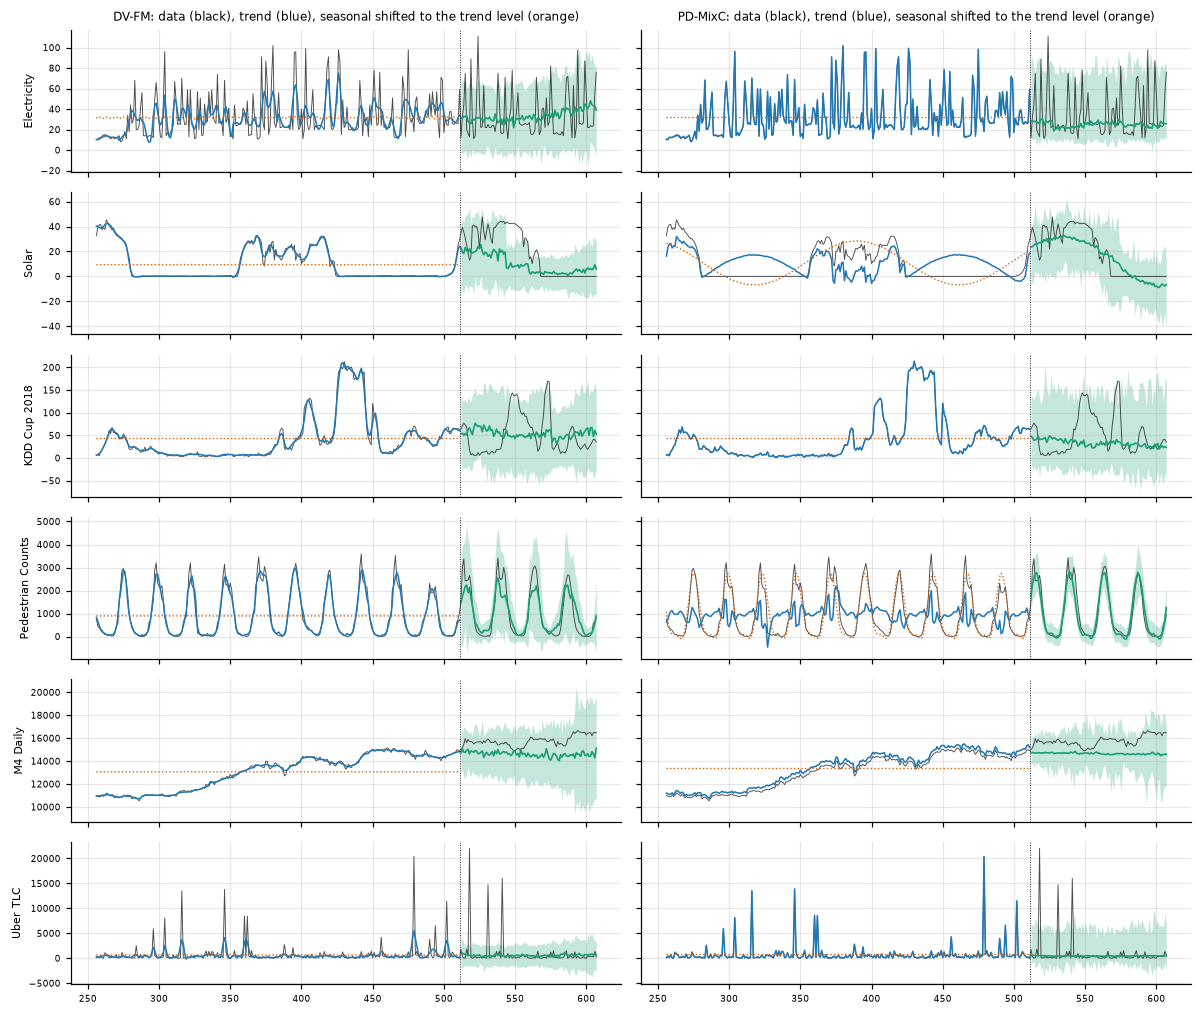

In [11]:
e = np.load(R/'examples_test_ood.npz', allow_pickle=True); T = int(e['context_length']); lv = list(e['quantile_levels'])
q05, q50, q95 = lv.index(.05), lv.index(.5), lv.index(.95)
ds = [str(v) for v in e['dataset']]; rows = [ds.index(v) for v in dict.fromkeys(ds)]
n = len(rows); t = np.arange(e['x'].shape[1]); show_from = T - 256
fig, ax = plt.subplots(n, 2, figsize=(11, 1.55*n), sharex=True, sharey='row')
for i, r in enumerate(rows):
    for c, name in enumerate(('DV-FM', 'PD-MixC')):
        a = ax[i, c]; q = e[f'{name}/quantiles'][:, r]
        a.plot(t[show_from:], e['x'][r, show_from:], color='k', lw=.6, alpha=.7)
        a.plot(t[show_from:T], e[f'{name}/trend'][r, show_from:T], color='#1f77b4', lw=1)
        a.plot(t[show_from:T], e[f'{name}/seasonal'][r, show_from:T] + e[f'{name}/trend'][r, show_from:T].mean(), color='#d95f02', lw=.9, ls=':')
        a.fill_between(t[T:], q[q05], q[q95], color='#1b9e77', alpha=.25, lw=0); a.plot(t[T:], q[q50], color='#1b9e77', lw=1.1)
        a.axvline(T - .5, color='k', lw=.6, ls=':')
        if c == 0: a.set_ylabel(str(e['dataset'][r]).replace('_', ' '), fontsize=7)
        if i == 0: a.set_title(f'{name}: data (black), trend (blue), seasonal shifted to the trend level (orange)', fontsize=8)
        a.tick_params(labelsize=6)
fig.tight_layout()